In [9]:
import re
import ollama
import pandas as pd

In [11]:


class GemmaQuantCoder:
    def __init__(self, model="gemma4:12b-it-qat", num_ctx=8192):
        self.model = model
        self.num_ctx = num_ctx
        self.history = []

    @staticmethod
    def _clean_gemma_thoughts(text: str) -> str:
        """Strip Gemma 4's internal <|channel>thought blocks before saving to multi-turn history."""
        # Removes <|channel>thought ... up to the final response channel or closing tag
        cleaned = re.sub(r"<\|channel\|?>thought.*?(?=<\|channel\|?>|\Z)", "", text, flags=re.DOTALL)
        cleaned = re.sub(r"<think>.*?</think>", "", cleaned, flags=re.DOTALL)
        return cleaned.strip()

    def chat(self, prompt: str, think: bool = True, reset: bool = False) -> str:
        """
        think=True  -> Prepends <|think|> to system prompt for complex Python/quant logic.
        think=False -> Direct, fast response without thinking token overhead.
        """
        think_prefix = "<|think|>\n" if think else ""
        sys_prompt = (
            f"{think_prefix}You are an expert quantitative risk analyst and Python developer. "
            "Write clean, vectorized pandas, numpy, and PyTorch code using the exact column names provided."
        )

        if reset or not self.history:
            self.history = [{"role": "system", "content": sys_prompt}]
        else:
            # Update system prompt in place so you can toggle thinking on/off between turns
            self.history[0]["content"] = sys_prompt

        self.history.append({"role": "user", "content": prompt})

        # Use low temperature (0.2) for direct coding, or higher (0.7-1.0) when thinking is active
        options = {
            "num_ctx": self.num_ctx,
            "temperature": 0.6 if think else 0.2,
            "top_p": 0.95,
            "top_k": 64
        }

        stream = ollama.chat(
            model=self.model,
            messages=self.history,
            stream=True,
            options=options
        )

        full_reply = ""
        for chunk in stream:
            piece = chunk["message"]["content"]
            print(piece, end="", flush=True)
            full_reply += piece
        print("\n")

        # Save only the clean final answer into multi-turn history (per Gemma 4 spec)
        clean_reply = self._clean_gemma_thoughts(full_reply)
        self.history.append({"role": "assistant", "content": clean_reply or full_reply})
        return full_reply





In [13]:
# Usage in JupyterLab:
coder = GemmaQuantCoder(model="gemma4:12b-it-qat", num_ctx=8192)

In [61]:
df_01 = pd.read_csv("vintage.csv") 

In [63]:
df = df_01.copy()

In [19]:
def get_dataframe_01(df_01: pd.DataFrame, max_full_dates: int = 40) -> str:
    # 1. Determine if the time axis / identifier is the Index or the First Column
    if isinstance(df_01.index, pd.DatetimeIndex) or df_01.index.name is not None:
        time_series = pd.Series(df_01.index, name=df_01.index.name or "Index")
        source_label = f"DataFrame Index ('{time_series.name}')"
    else:
        time_series = df_01.iloc[:, 0]
        source_label = f"First Column ('{time_series.name}')"

    # 2. Extract sorted unique values from the first column / index
    unique_vals = pd.Series(time_series.dropna().unique()).sort_values().reset_index(drop=True)
    n_unique = len(unique_vals)

    # Calculate time step / granularity if convertible to datetime
    granularity_note = ""
    try:
        dt_vals = pd.to_datetime(unique_vals)
        diffs = dt_vals.diff().dropna()
        if not diffs.empty:
            most_common_step = diffs.mode().iloc[0]
            granularity_note = f" | Modal Time Step: {most_common_step}"
    except Exception:
        pass

    # If unique dates are <= 40 (e.g., monthly/quarterly cohorts), show ALL of them.
    # Otherwise, show the first 5 and last 5 unique dates so we don't blow up num_ctx=8192.
    if n_unique <= max_full_dates:
        date_values_str = f"All {n_unique} unique values: {unique_vals.astype(str).tolist()}"
    else:
        first_5 = unique_vals.head(5).astype(str).tolist()
        last_5 = unique_vals.tail(5).astype(str).tolist()
        date_values_str = (
            f"{n_unique} unique values from {first_5[0]} to {last_5[-1]}\n"
            f"- Earliest 5 unique dates: {first_5}\n"
            f"- Latest 5 unique dates:   {last_5}"
        )

    time_profile = (
        f"### Time / Primary Axis Profile ({source_label}{granularity_note}):\n"
        f"{date_values_str}"
    )

    schema_df = pd.DataFrame({
        "Data Type": df_01.dtypes.astype(str),
        "Missing": df_01.isna().sum(),
        "Unique Count": df_01.nunique(),
        "Min": [df_01[c].dropna().min() if not df_01[c].dropna().empty else None for c in df_01.columns],
        "Max": [df_01[c].dropna().max() if not df_01[c].dropna().empty else None for c in df_01.columns],
    })
    schema_df.index.name = "Column"

    # 4. Show First 5 rows AND Last 5 rows (instead of just head(10))
    head_md = df_01.head(5).to_markdown()
    tail_md = df_01.tail(5).to_markdown()

    return (
        f"### Dataset Shape: {df_01.shape[0]} rows, {df_01.shape[1]} columns\n\n"
        f"{time_profile}\n\n"
        f"### Column Schema:\n{schema_df.to_markdown()}\n\n"
        f"### First 5 Rows (Earliest):\n{head_md}\n\n"
        f"### Last 5 Rows (Latest):\n{tail_md}"
    )

# Generate the context and inspect it
data_context_01 = get_dataframe_01(df_01)
print(data_context_01)


### Dataset Shape: 116 rows, 31 columns

### Time / Primary Axis Profile (First Column ('Indicator')):
All 4 unique values: ['reported overdue >=31D balance', 'reported overdue >=61D balance', 'reported overdue >=91D balance', 'reported overdue>=1D balance']

### Column Schema:
| Column                    | Data Type   |   Missing |   Unique Count | Min                            | Max                          |
|:--------------------------|:------------|----------:|---------------:|:-------------------------------|:-----------------------------|
| Indicator                 | object      |         0 |              4 | reported overdue >=31D balance | reported overdue>=1D balance |
| Period                    | object      |         0 |             29 | 1/1/17                         | 9/1/18                       |
| disbursement amonut       | object      |         0 |             29 | 112,712,022                    | 89,136,383                   |
| 0（monthly disbursement） | object  

/var/folders/8w/mpz_tvmj7b98g9wp3y5d2r3m0000gn/T/ipykernel_54393/2156822827.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dt_vals = pd.to_datetime(unique_vals)


In [ ]:
# Pass your dataframe context and request vectorized Python code:

In [21]:
coder.chat(f"""
Here are columns of the dataframe `df_01`, named vintage:
{data_context_01}

we need to perform: MOB Vintage decomposition and cohort resolition
namely, demonstrate Months-on-Book(MOB) cohort decomposition by separating cumulative threshold balances
(1D+,30D+, 60D+,90D+) into discrete marginal aging buckets.
cohort roll and cure mechanics:
MOB 0 to MOB 1,
MOB 1 to MOB 2,
MOB 2 to MOB 3

Before writing any code, let's confirm the methodology and formulae.


""", think=True)

To perform a rigorous **MOB (Months-on-Book) Vintage Decomposition**, we must first transform the data from a "long" format (where indicators are rows) into a "wide" format (where indicators are columns). This allows us to perform vectorized subtractions to isolate marginal buckets and calculate transition dynamics.

### Methodology & Formulae

**1. Data Normalization:**
*   **Clean Amount:** Remove commas and convert `disbursement amonut` and all numeric columns to `float64`.
*   **Pivot:** Reshape the data so each row is a unique `Period` and columns represent the cumulative balances for each `Indicator` at each `MOB`.

**2. Marginal Bucket Decomposition:**
Since the indicators are cumulative (e.g., $\ge 31D$ includes everyone who is $\ge 61D$), we calculate the discrete marginal buckets:
*   **Bucket 1 (1-30D):** $M_1 = \text{Bal}(\ge 1D) - \text{Bal}(\ge 31D)$
*   **Bucket 2 (31-60D):** $M_2 = \text{Bal}(\ge 31D) - \text{Bal}(\ge 61D)$
*   **Bucket 3 (61-90D):** $M_3 = \text{Bal}(\

'To perform a rigorous **MOB (Months-on-Book) Vintage Decomposition**, we must first transform the data from a "long" format (where indicators are rows) into a "wide" format (where indicators are columns). This allows us to perform vectorized subtractions to isolate marginal buckets and calculate transition dynamics.\n\n### Methodology & Formulae\n\n**1. Data Normalization:**\n*   **Clean Amount:** Remove commas and convert `disbursement amonut` and all numeric columns to `float64`.\n*   **Pivot:** Reshape the data so each row is a unique `Period` and columns represent the cumulative balances for each `Indicator` at each `MOB`.\n\n**2. Marginal Bucket Decomposition:**\nSince the indicators are cumulative (e.g., $\\ge 31D$ includes everyone who is $\\ge 61D$), we calculate the discrete marginal buckets:\n*   **Bucket 1 (1-30D):** $M_1 = \\text{Bal}(\\ge 1D) - \\text{Bal}(\\ge 31D)$\n*   **Bucket 2 (31-60D):** $M_2 = \\text{Bal}(\\ge 31D) - \\text{Bal}(\\ge 61D)$\n*   **Bucket 3 (61-90D)

In [27]:
coder.chat("""
yeah, could you continue the python codes?
# Separate Roll and Cure

""", think=True)

To perform a professional **MOB Vintage Decomposition**, we need to transform the cumulative indicators into discrete marginal buckets and then calculate the transition dynamics (Rolls and Cures). 

Below is the production-grade Python code. It uses `pandas` for the heavy lifting of data manipulation and `numpy` for vectorized logic. I have included a `PyTorch` block at the end to demonstrate how to convert these results into a tensor for further risk modeling (e.g., predicting future roll rates).

```python
import pandas as pd
import numpy as np
import torch

def perform_vintage_decomposition(df: pd.DataFrame) -> pd.DataFrame:
    """
    Performs MOB Vintage Decomposition:
    1. Converts cumulative indicators to marginal buckets (1-30D, 31-60D, 61-90D, 91D+).
    2. Calculates Roll and Cure mechanics between MOB 0->1, 1->2, and 2->3.
    """
    df = df.copy()
    
    # --- 1. Data Cleaning ---
    # Remove commas from disbursement amount and convert to float
    df['disbursement a

'To perform a professional **MOB Vintage Decomposition**, we need to transform the cumulative indicators into discrete marginal buckets and then calculate the transition dynamics (Rolls and Cures). \n\nBelow is the production-grade Python code. It uses `pandas` for the heavy lifting of data manipulation and `numpy` for vectorized logic. I have included a `PyTorch` block at the end to demonstrate how to convert these results into a tensor for further risk modeling (e.g., predicting future roll rates).\n\n```python\nimport pandas as pd\nimport numpy as np\nimport torch\n\ndef perform_vintage_decomposition(df: pd.DataFrame) -> pd.DataFrame:\n    """\n    Performs MOB Vintage Decomposition:\n    1. Converts cumulative indicators to marginal buckets (1-30D, 31-60D, 61-90D, 91D+).\n    2. Calculates Roll and Cure mechanics between MOB 0->1, 1->2, and 2->3.\n    """\n    df = df.copy()\n    \n    # --- 1. Data Cleaning ---\n    # Remove commas from disbursement amount and convert to float\n  

In [29]:
coder.chat("""
yeah, could you continue the python codes?
# 2. Convert to PyTorch for Risk Modeling
""", think=True)

Continuing from the previous step, here is the completion of the code. This section handles the conversion from the processed pandas DataFrame into a PyTorch tensor, includes a normalization step (standard for risk modeling), and provides a sample **Multi-Layer Perceptron (MLP)** architecture to predict future roll rates based on historical vintage behavior.

```python
# ... (continuing from the previous code block)

# 2. Convert to PyTorch for Risk Modeling

# Identify all Roll Rate columns generated in the decomposition
roll_rate_cols = [col for col in df_resolved.columns if col.startswith('Roll_Rate_')]

# Extract the features (Roll Rates) and the target (e.g., the last transition as a target)
# We use .values to get the underlying numpy array, then convert to a PyTorch tensor
# Shape: (Number of Periods, Number of Transitions)
X_df = df_resolved[roll_rate_cols]
X_tensor = torch.tensor(X_df.values, dtype=torch.float32)

# Handle NaN values (if any remain) by zero-filling
X_tensor = 

'Continuing from the previous step, here is the completion of the code. This section handles the conversion from the processed pandas DataFrame into a PyTorch tensor, includes a normalization step (standard for risk modeling), and provides a sample **Multi-Layer Perceptron (MLP)** architecture to predict future roll rates based on historical vintage behavior.\n\n```python\n# ... (continuing from the previous code block)\n\n# 2. Convert to PyTorch for Risk Modeling\n\n# Identify all Roll Rate columns generated in the decomposition\nroll_rate_cols = [col for col in df_resolved.columns if col.startswith(\'Roll_Rate_\')]\n\n# Extract the features (Roll Rates) and the target (e.g., the last transition as a target)\n# We use .values to get the underlying numpy array, then convert to a PyTorch tensor\n# Shape: (Number of Periods, Number of Transitions)\nX_df = df_resolved[roll_rate_cols]\nX_tensor = torch.tensor(X_df.values, dtype=torch.float32)\n\n# Handle NaN values (if any remain) by zero-

In [31]:
coder.chat("""
yeah, could you continue the Key Quantitative Explanations
# 3. Flow Dynamics 
""", think=True)

''

In [ ]:
import pandas as pd
import numpy as np

In [194]:
df_01 = pd.read_csv("vintage.csv") 

In [196]:
df = df_01.copy()

In [148]:
# === Cell 1: Config + import + clean ===


MOB0     = '0 (monthly disbursement)'
MOB_COLS = [MOB0] + [str(i) for i in range(1, 13)]
IND = {
    'reported overdue>=1D balance':   1,   # bucket id 1  (1-30D cum)
    'reported overdue >=31D balance': 2,
    'reported overdue >=61D balance': 3,
    'reported overdue >=91D balance': 4,
}
BUCKET_LABEL = {1: '1-30D', 2: '31-60D', 3: '61-90D', 4: '90D+'}

def clean(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df.drop(columns=[c for c in df.columns
                          if c.startswith('Unnamed')
                          or c.endswith('.1')
                          or c == '0（放款当月）'], errors='ignore')
    df['disbursement amount'] = (df['disbursement amount'].astype(str)
                                   .str.replace(',', '', regex=False))
    df['disbursement amount'] = pd.to_numeric(df['disbursement amount'], errors='coerce')
    df[MOB_COLS] = df[MOB_COLS].replace('-', 0)
    df[MOB_COLS] = df[MOB_COLS].apply(pd.to_numeric, errors='coerce')
    df['Period'] = pd.to_datetime(df['Period'], format='%m/%d/%y', errors='coerce')
    return df[['Period', 'Indicator', 'disbursement amount'] + MOB_COLS]

In [150]:
# === Cell 2: Pivot, strict hierarchy drop, triangle mask ===
def pivot_validate_mask(df):
    # index=Period, cols=(Indicator_id, MOB) — Indicator_id is int 1..4
    raw = (df.assign(Indicator=df['Indicator'].map(IND))
             .set_index(['Period', 'Indicator'])[MOB_COLS + ['disbursement amount']]
             .unstack(level=1)
             .swaplevel(0, 1, axis=1)
             .sort_index(axis=1))

    # --- hierarchy check (raw, on cleaned '-' -> 0) ---
    viol = pd.DataFrame(False, index=raw.index, columns=MOB_COLS)
    for mob in MOB_COLS:
        for lo, hi in [(1, 2), (2, 3), (3, 4)]:
            if (lo, mob) in raw.columns and (hi, mob) in raw.columns:
                viol[mob] |= (raw[(lo, mob)] < raw[(hi, mob)]).fillna(False)

    bad = viol.any(axis=1)
    if bad.any():
        first_bad_mob = viol.loc[bad].idxmax(axis=1)
        print(f"Strict drop: {bad.sum()} vintage(s) with hierarchy violation")
        print(pd.DataFrame({'Period': bad[bad].index,
                            'first_violating_MOB': first_bad_mob.values})
                .to_string(index=False))
    p = raw.loc[~bad].copy()

    # --- triangle mask: MOB > vintage age  ->  NaN (not yet observed) ---
    if len(p):
        v_idx   = p.index.year * 12 + p.index.month
        max_obs = v_idx.max() - v_idx           # months elapsed per vintage
        for i, mob in enumerate(MOB_COLS):
            beyond = max_obs.values < i
            for b in IND.values():
                if (b, mob) in p.columns:
                    p[(b, mob)] = p[(b, mob)].where(~beyond)

    return p, bad

In [178]:
# === Cell 3: Decomposition (wide + long) ===
def decompose(p):
    wide = {}
    for i, mob in enumerate(MOB_COLS):
        cum = {b: p[(b, mob)] if (b, mob) in p.columns else pd.Series(np.nan, index=p.index)
               for b in (1, 2, 3, 4)}
        d = pd.DataFrame({
            '1-30D':  cum[1] - cum[2],
            '31-60D': cum[2] - cum[3],
            '61-90D': cum[3] - cum[4],
            '90D+':   cum[4],
        })
        d['MOB'] = i
        wide[mob] = d
    wide_df = pd.concat([d.assign(Period=p.index) for d in wide.values()], ignore_index=True)
    long_df = wide_df.melt(id_vars=['Period', 'MOB'],
                           var_name='bucket', value_name='balance')
    wide_df = wide_df[['Period', 'MOB', '1-30D', '31-60D', '61-90D', '90D+']]
    return wide_df, long_df


In [180]:
# === Cell 4: Roll / cure tables for all 11 transitions ===
def roll_cure(wide, p, include_flow=True):
    D = p[(1, 'disbursement_amount')]           # one value per vintage
    pairs = [('1-30D', '31-60D'), ('31-60D', '61-90D'), ('61-90D', '90D+')]
    frames = []
    for k in range(12):
        Ma = (wide[wide['MOB'] == k ].set_index('Period')[['1-30D', '31-60D', '61-90D', '90D+']])
        Mb = (wide[wide['MOB'] == k+1].set_index('Period')[['1-30D', '31-60D', '61-90D', '90D+']])
        for src, dst in pairs:
            num_roll = (Mb[dst] - Ma[dst]).clip(lower=0)
            num_cure = (Ma[dst] - Mb[dst]).clip(lower=0)
            den      = Ma[src]
            row = pd.DataFrame({
                'Period':       Ma.index,
                'transition':   f'{k}->{k+1}',
                'from_MOB':     k, 'to_MOB': k+1,
                'roll_pair':    f'{src}->{dst}',
                'denominator':  den,
                'num_roll':     num_roll,
                'num_cure':     num_cure,
                'roll_rate':    (num_roll / den).where(den > 0),
                'cure_rate':    (num_cure / den).where(den > 0),
            })
            if include_flow:
                w = D.reindex(Ma.index)
                row['roll_flow_rate'] = (num_roll / w).where(w > 0)
                row['cure_flow_rate'] = (num_cure / w).where(w > 0)
            frames.append(row)
    return pd.concat(frames, ignore_index=True).sort_values(['transition', 'roll_pair', 'Period'])


In [182]:
# === Cell 5: Pooled, disbursement-weighted, with n_v ===
def pool(rates, p):
    D = p[(1, 'disbursement_amount')]
    def _agg(g):
        w  = D.reindex(g['Period']).values
        ok = g['roll_rate'].notna().values
        okc = g['cure_rate'].notna().values
        return pd.Series({
            'n_vintages_roll':  int(ok.sum()),
            'n_vintages_cure':  int(okc.sum()),
            'roll_pooled':      np.average(g['roll_rate'][ok],  weights=w[ok])  if ok.any()  else np.nan,
            'cure_pooled':      np.average(g['cure_rate'][okc], weights=w[okc]) if okc.any() else np.nan,
            'roll_flow_pooled': (g['num_roll'][ok].sum() / w[ok].sum())  if ok.any()  else np.nan,
            'cure_flow_pooled': (g['num_cure'][okc].sum() / w[okc].sum()) if okc.any() else np.nan,
        })
    return (rates.groupby(['transition', 'roll_pair'])
                  .apply(_agg, include_groups=False)
                  .reset_index())

In [ ]:
# === Cell 6: Run & display ===
df_clean  = clean(pd.read_csv("vintage.csv"))
p, dropped = pivot_validate_mask(df_clean)

wide_dec, long_dec = decompose(p)
rc_tbl             = roll_cure(wide_dec, p)
pooled             = pool(rc_tbl, p)

print("\nVintages retained:", len(p), "| dropped:", int(dropped.sum()))
print("\nDecomposition (wide) head:")
print(wide_dec.head(10).to_string(index=False))
print("\nRoll/cure (one transition, one pair):")
print(rc_tbl.query("transition=='0->1' and roll_pair=='1-30D->31-60D'")
             .head(10).to_string(index=False))
print("\nPooled disbursement-weighted:")
print(pooled.to_string(index=False))

In [146]:
# Check if columns have hidden spaces
print("--- Columns ---")
for col in df_01.columns:
    print(f"'{col}'") # The quotes will reveal leading/trailing spaces

# Check if Indicator values have hidden spaces
print("\n--- Indicator Values ---")
for val in df_01['Indicator'].unique():
    print(f"'{val}'")

--- Columns ---
'Indicator'
'Period'
'disbursement amount'
'0 (monthly disbursement)'
'1'
'2'
'3'
'4'
'5'
'6'
'7'
'8'
'9'
'10'
'11'
'12'

--- Indicator Values ---
'reported overdue>=1D balance'
'reported overdue>=31D balance'
'reported overdue>=61D balance'
'reported overdue>=91D balance'


In [198]:


# Define the clean names
MOB_COLS = ['MOB_0'] + [str(i) for i in range(1, 13)]
IND = {
    'reported overdue>=1D balance':   1,
    'reported overdue >=31D balance': 2,
    'reported overdue >=61D balance': 3,
    'reported overdue >=91D balance': 4,
}

def load_and_pivot(df):
    # 1. Safe type conversion (no commas, no hyphens to worry about!)
    df[MOB_COLS] = df[MOB_COLS].apply(pd.to_numeric, errors='coerce').fillna(0)
    df['disbursement_amount'] = pd.to_numeric(df['disbursement_amount'], errors='coerce')
    df['Period'] = pd.to_datetime(df['Period'], format='%m/%d/%y')
    
    # 2. Map Indicators
    df['Indicator'] = df['Indicator'].map(IND)
    
    # 3. Pivot
    raw = (df.set_index(['Period', 'Indicator'])[MOB_COLS + ['disbursement_amount']]
             .unstack(level=1)
             .swaplevel(0, 1, axis=1)
             .sort_index(axis=1))

    # 4. Hierarchy Check
    viol = pd.DataFrame(False, index=raw.index, columns=MOB_COLS)
    for mob in MOB_COLS:
        for lo, hi in [(1, 2), (2, 3), (3, 4)]:
            if (lo, mob) in raw.columns and (hi, mob) in raw.columns:
                viol[mob] |= (raw[(lo, mob)] < raw[(hi, mob)])
                
    bad = viol.any(axis=1)
    if bad.any():
        print(f"Strict drop: {bad.sum()} vintage(s) with hierarchy violation")
    p = raw.loc[~bad].copy()

    # 5. Triangle Mask
    if len(p):
        v_idx   = p.index.year * 12 + p.index.month
        max_obs = v_idx.max() - v_idx
        for i, mob in enumerate(MOB_COLS):
            beyond = max_obs.values < i
            for b in [1, 2, 3, 4]:
                if (b, mob) in p.columns:
                    p[(b, mob)] = p[(b, mob)].where(~beyond)

    return p, bad

In [ ]:
# --- 3. Decomposition ---
def decompose(p):
    wide = {}
    for i, mob in enumerate(MOB_COLS):
        cum = {b: p[(b, mob)] if (b, mob) in p.columns else pd.Series(np.nan, index=p.index) for b in (1, 2, 3, 4)}
        d = pd.DataFrame({
            '1-30D':  cum[1] - cum[2],
            '31-60D': cum[2] - cum[3],
            '61-90D': cum[3] - cum[4],
            '90D+':   cum[4],
        })
        d['MOB'] = i
        wide[mob] = d
        
    wide_df = pd.concat([d.assign(Period=p.index) for d in wide.values()], ignore_index=True)
    long_df = wide_df.melt(id_vars=['Period', 'MOB'], var_name='bucket', value_name='balance')
    return wide_df[['Period', 'MOB', '1-30D', '31-60D', '61-90D', '90D+']], long_df

In [ ]:
# --- 4. Roll / Cure ---
def roll_cure(wide, p):
    D = p[(1, 'disbursement_amount')]           
    pairs = [('1-30D', '31-60D'), ('31-60D', '61-90D'), ('61-90D', '90D+')]
    frames = []
    
    for k in range(12):
        Ma = wide[wide['MOB'] == k ].set_index('Period')[['1-30D', '31-60D', '61-90D', '90D+']]
        Mb = wide[wide['MOB'] == k+1].set_index('Period')[['1-30D', '31-60D', '61-90D', '90D+']]
        
        for src, dst in pairs:
            num_roll = (Mb[dst] - Ma[dst]).clip(lower=0)
            num_cure = (Ma[dst] - Mb[dst]).clip(lower=0)
            den      = Ma[src]
            w        = D.reindex(Ma.index)
            
            frames.append(pd.DataFrame({
                'Period':       Ma.index,
                'transition':   f'{k}->{k+1}',
                'roll_pair':    f'{src}->{dst}',
                'denominator':  den,
                'num_roll':     num_roll,
                'num_cure':     num_cure,
                'roll_rate':    (num_roll / den).where(den > 0),
                'cure_rate':    (num_cure / den).where(den > 0),
                'roll_flow_rate': (num_roll / w).where(w > 0),
                'cure_flow_rate': (num_cure / w).where(w > 0),
            }))
            
    return pd.concat(frames, ignore_index=True).sort_values(['transition', 'roll_pair', 'Period'])

In [ ]:
# --- 5. Pool ---
def pool(rates, p):
    D = p[(1, 'disbursement_amount')]
    def _agg(g):
        w  = D.reindex(g['Period']).values
        ok = g['roll_rate'].notna().values
        return pd.Series({
            'n_vintages': int(ok.sum()),
            'roll_pooled':      np.average(g['roll_rate'][ok], weights=w[ok]) if ok.any() else np.nan,
            'cure_pooled':      np.average(g['cure_rate'][ok], weights=w[ok]) if ok.any() else np.nan,
            'roll_flow_pooled': (g['num_roll'][ok].sum() / w[ok].sum())  if ok.any() else np.nan,
        })
    return rates.groupby(['transition', 'roll_pair']).apply(_agg).reset_index()

# === EXECUTE ===
p, dropped = pivot_validate_mask(df_raw)
wide_dec, long_dec = decompose(p)
rc_tbl = roll_cure(wide_dec, p)
pooled = pool(rc_tbl, p)

print(f"Vintages retained: {len(p)} | dropped: {int(dropped.sum())}")
print(wide_dec.head())

In [216]:


# 1. Load the cleaned CSV
df_raw = pd.read_csv("vintage.csv")

# Drop the empty column if it exists
if 'Unnamed: 16' in df_raw.columns:
    df_raw = df_raw.drop(columns=['Unnamed: 16'])

# --- Configuration ---
MOB_COLS = ['MOB_0'] + [str(i) for i in range(1, 13)]
IND = {
    'reported overdue>=1D balance':   1,
    'reported overdue>=31D balance': 2,
    'reported overdue>=61D balance': 3,
    'reported overdue>=91D balance': 4,
}

# --- 2. Pivot & Validate ---
def load_and_pivot(df):
    df = df.copy()
    
    # Ensure correct types
    df['Period'] = pd.to_datetime(df['Period'], format='%m/%d/%y')
    df['Indicator'] = df['Indicator'].map(IND)
    
    # Pivot: index=(Period, Indicator), columns=MOB
    raw = (df.set_index(['Period', 'Indicator'])[MOB_COLS + ['disbursement_amount']]
             .unstack(level=1)
             .swaplevel(0, 1, axis=1)
             .sort_index(axis=1))

    # Hierarchy Check (Strict drop)
    viol = pd.DataFrame(False, index=raw.index, columns=MOB_COLS)
    for mob in MOB_COLS:
        for lo, hi in [(1, 2), (2, 3), (3, 4)]:
            if (lo, mob) in raw.columns and (hi, mob) in raw.columns:
                viol[mob] |= (raw[(lo, mob)] < raw[(hi, mob)])
                
    bad = viol.any(axis=1)
    if bad.any():
        print(f"Strict drop: {bad.sum()} vintage(s) with hierarchy violation")
    p = raw.loc[~bad].copy()

    # Triangle Mask (Unobserved MOBs = NaN)
    if len(p):
        v_idx   = p.index.year * 12 + p.index.month
        max_obs = v_idx.max() - v_idx
        for i, mob in enumerate(MOB_COLS):
            beyond = max_obs.values < i
            for b in [1, 2, 3, 4]:
                if (b, mob) in p.columns:
                    p[(b, mob)] = p[(b, mob)].where(~beyond)

    return p, bad

# --- 3. Decomposition ---
def decompose(p):
    wide = {}
    for i, mob in enumerate(MOB_COLS):
        cum = {b: p[(b, mob)] if (b, mob) in p.columns else pd.Series(np.nan, index=p.index) for b in (1, 2, 3, 4)}
        d = pd.DataFrame({
            '1-30D':  cum[1] - cum[2],
            '31-60D': cum[2] - cum[3],
            '61-90D': cum[3] - cum[4],
            '90D+':   cum[4],
        })
        d['MOB'] = i
        wide[mob] = d
        
    wide_df = pd.concat([d.assign(Period=p.index) for d in wide.values()], ignore_index=True)
    long_df = wide_df.melt(id_vars=['Period', 'MOB'], var_name='bucket', value_name='balance')
    return wide_df[['Period', 'MOB', '1-30D', '31-60D', '61-90D', '90D+']], long_df

# --- 4. Roll / Cure ---
def roll_cure(wide, p):
    D = p[(1, 'disbursement_amount')]           
    pairs = [('1-30D', '31-60D'), ('31-60D', '61-90D'), ('61-90D', '90D+')]
    frames = []
    
    for k in range(12):
        Ma = wide[wide['MOB'] == k ].set_index('Period')[['1-30D', '31-60D', '61-90D', '90D+']]
        Mb = wide[wide['MOB'] == k+1].set_index('Period')[['1-30D', '31-60D', '61-90D', '90D+']]
        
        for src, dst in pairs:
            num_roll = (Mb[dst] - Ma[dst]).clip(lower=0)
            num_cure = (Ma[dst] - Mb[dst]).clip(lower=0)
            den      = Ma[src]
            w        = D.reindex(Ma.index)
            
            frames.append(pd.DataFrame({
                'Period':         Ma.index,
                'transition':     f'{k}->{k+1}',
                'roll_pair':      f'{src}->{dst}',
                'denominator':    den,
                'num_roll':       num_roll,
                'num_cure':       num_cure,
                'roll_rate':      (num_roll / den).where(den > 0),
                'cure_rate':      (num_cure / den).where(den > 0),
                'roll_flow_rate': (num_roll / w).where(w > 0),
                'cure_flow_rate': (num_cure / w).where(w > 0),
            }))
            
    return pd.concat(frames, ignore_index=True).sort_values(['transition', 'roll_pair', 'Period'])

# --- 5. Pool ---
def pool(rates, p):
    D = p[(1, 'disbursement_amount')]
    def _agg(g):
        w  = D.reindex(g['Period']).values
        ok = g['roll_rate'].notna().values
        okc = g['cure_rate'].notna().values
        return pd.Series({
            'n_vintages_roll':  int(ok.sum()),
            'n_vintages_cure':  int(okc.sum()),
            'roll_pooled':      np.average(g['roll_rate'][ok], weights=w[ok]) if ok.any() else np.nan,
            'cure_pooled':      np.average(g['cure_rate'][okc], weights=w[okc]) if okc.any() else np.nan,
            'roll_flow_pooled': (g['num_roll'][ok].sum() / w[ok].sum()) if ok.any() else np.nan,
            'cure_flow_pooled': (g['num_cure'][okc].sum() / w[okc].sum()) if okc.any() else np.nan,
        })
    return rates.groupby(['transition', 'roll_pair']).apply(_agg, include_groups=False).reset_index()


# ==========================================
# RUN PIPELINE
# ==========================================
p, dropped = load_and_pivot(df_raw)
wide_dec, long_dec = decompose(p)
rc_tbl = roll_cure(wide_dec, p)
pooled = pool(rc_tbl, p)

print(f"Vintages retained: {len(p)} | dropped: {int(dropped.sum())}")
print("\n--- Decomposition (wide) Head ---")
print(wide_dec.head(10).to_string(index=False))

print("\n--- Roll/Cure Rates (MOB 0->1) Head ---")
print(rc_tbl[rc_tbl['transition'] == '0->1'].head(10).to_string(index=False))

print("\n--- Pooled Disbursement-Weighted Results ---")
print(pooled.head(9).to_string(index=False))

Vintages retained: 29 | dropped: 0

--- Decomposition (wide) Head ---
    Period  MOB     1-30D  31-60D  61-90D  90D+
2017-01-01    0 3094523.0     0.0     0.0   0.0
2017-02-01    0 2248275.0     0.0     0.0   0.0
2017-03-01    0 1379600.0     0.0     0.0   0.0
2017-04-01    0 9257439.0     0.0     0.0   0.0
2017-05-01    0 6294434.0     0.0     0.0   0.0
2017-06-01    0 8013662.0     0.0     0.0   0.0
2017-07-01    0 4100105.0     0.0     0.0   0.0
2017-08-01    0 6179364.0     0.0     0.0   0.0
2017-09-01    0 5466847.0     0.0     0.0   0.0
2017-10-01    0 8684893.0     0.0     0.0   0.0

--- Roll/Cure Rates (MOB 0->1) Head ---
    Period transition     roll_pair  denominator  num_roll  num_cure  roll_rate  cure_rate  roll_flow_rate  cure_flow_rate
2017-01-01       0->1 1-30D->31-60D    3094523.0  627000.0       0.0   0.202616        0.0        0.005563             0.0
2017-02-01       0->1 1-30D->31-60D    2248275.0  200000.0       0.0   0.088957        0.0        0.001483         

In [222]:
wide_dec.to_excel('decomposition.xlsx')

In [223]:
pooled.to_excel('pooled_rates.xlsx')

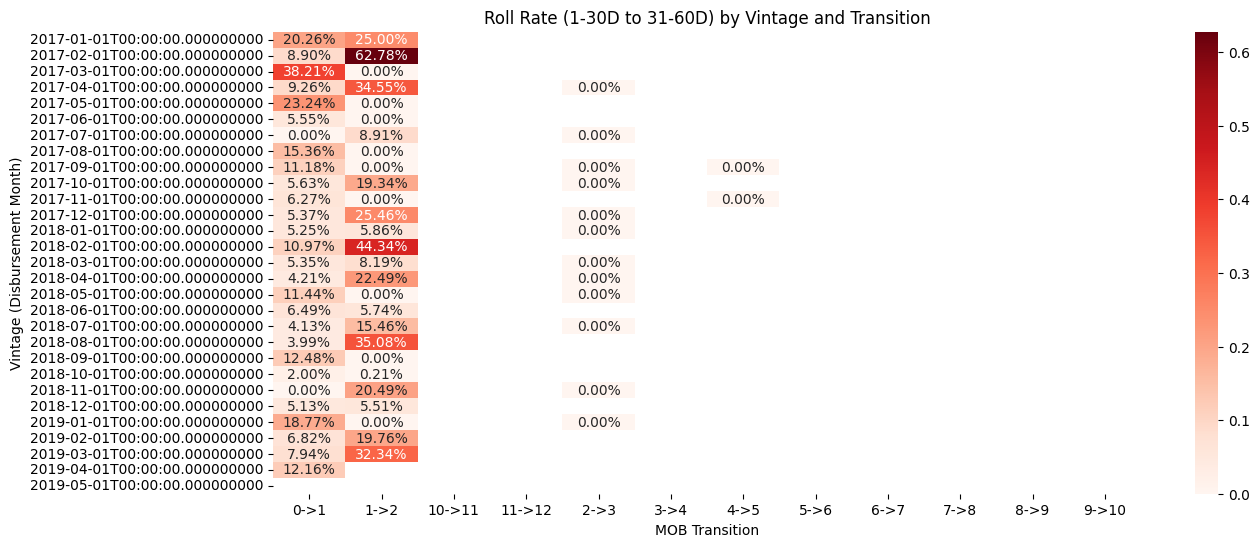

In [226]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for just the 1-30D -> 31-60D roll rate
heatmap_data = rc_tbl[rc_tbl['roll_pair'] == '1-30D->31-60D'].pivot(
    index='Period', columns='transition', values='roll_rate'
)

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_data, annot=True, cmap='Reds', fmt='.2%')
plt.title('Roll Rate (1-30D to 31-60D) by Vintage and Transition')
plt.ylabel('Vintage (Disbursement Month)')
plt.xlabel('MOB Transition')
plt.show()

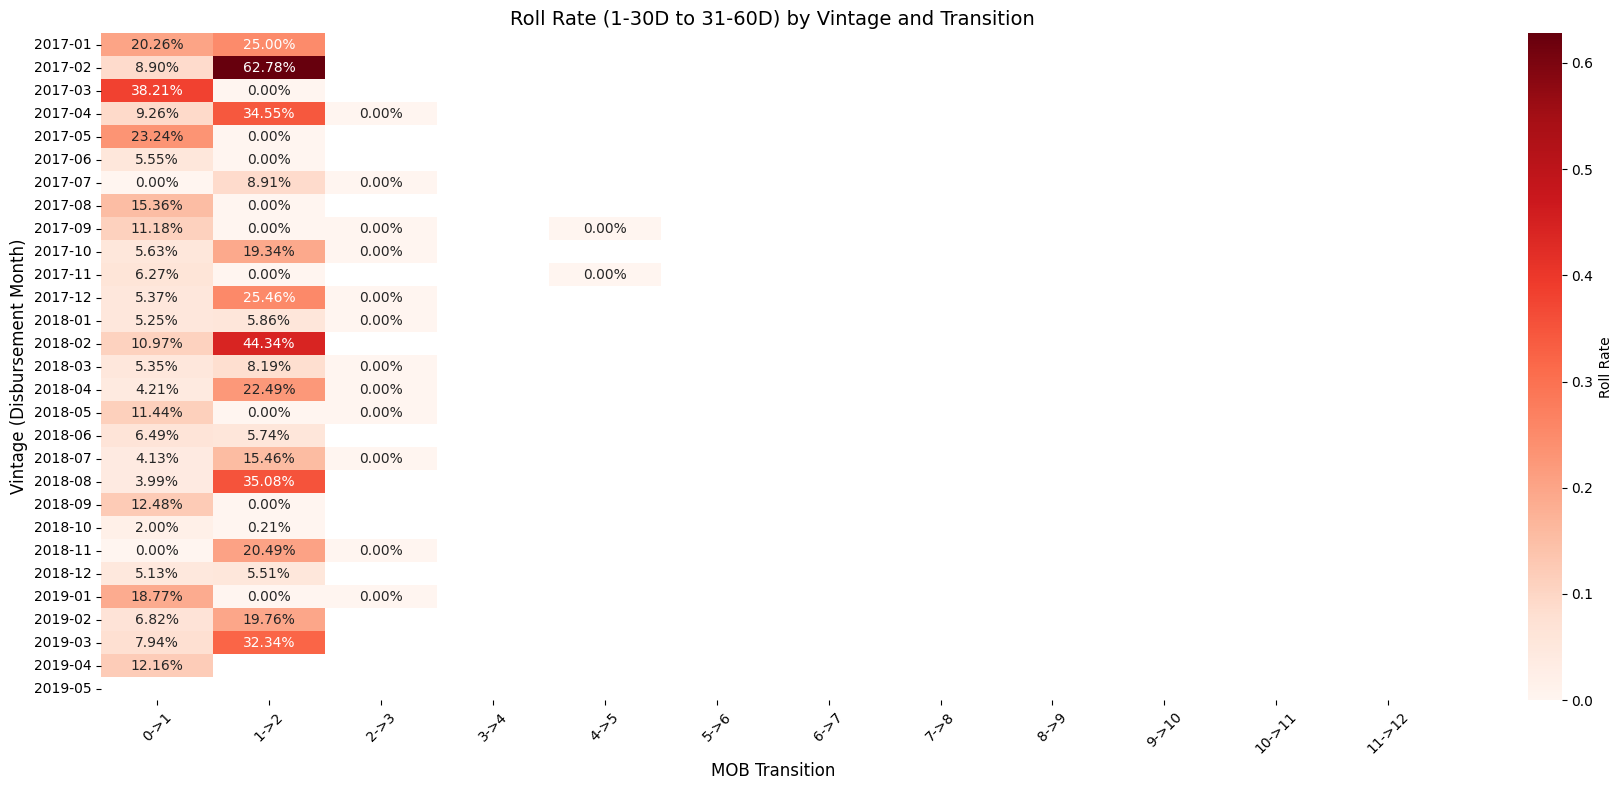

In [228]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Filter for just the 1-30D -> 31-60D roll rate
heatmap_data = rc_tbl[rc_tbl['roll_pair'] == '1-30D->31-60D'].copy()

# 2. Format Y-axis (Period) to just 'YYYY-MM'
heatmap_data['Period_str'] = heatmap_data['Period'].dt.strftime('%Y-%m')

# 3. Force X-axis (transitions) to sort numerically
transitions_ordered = [f'{i}->{i+1}' for i in range(12)]
heatmap_data['transition'] = pd.Categorical(
    heatmap_data['transition'], 
    categories=transitions_ordered, 
    ordered=True
)

# 4. Pivot
pivot_data = heatmap_data.pivot(
    index='Period_str', 
    columns='transition', 
    values='roll_rate'
)

# 5. Plot
plt.figure(figsize=(18, 8))
sns.heatmap(
    pivot_data, 
    annot=True, 
    cmap='Reds', 
    fmt='.2%',     # Shows as 20.26% instead of 0.2026
    cbar_kws={'label': 'Roll Rate'}
)

plt.title('Roll Rate (1-30D to 31-60D) by Vintage and Transition', fontsize=14)
plt.ylabel('Vintage (Disbursement Month)', fontsize=12)
plt.xlabel('MOB Transition', fontsize=12)
plt.xticks(rotation=45) # Rotates the X labels so they don't overlap
plt.tight_layout()
plt.show()

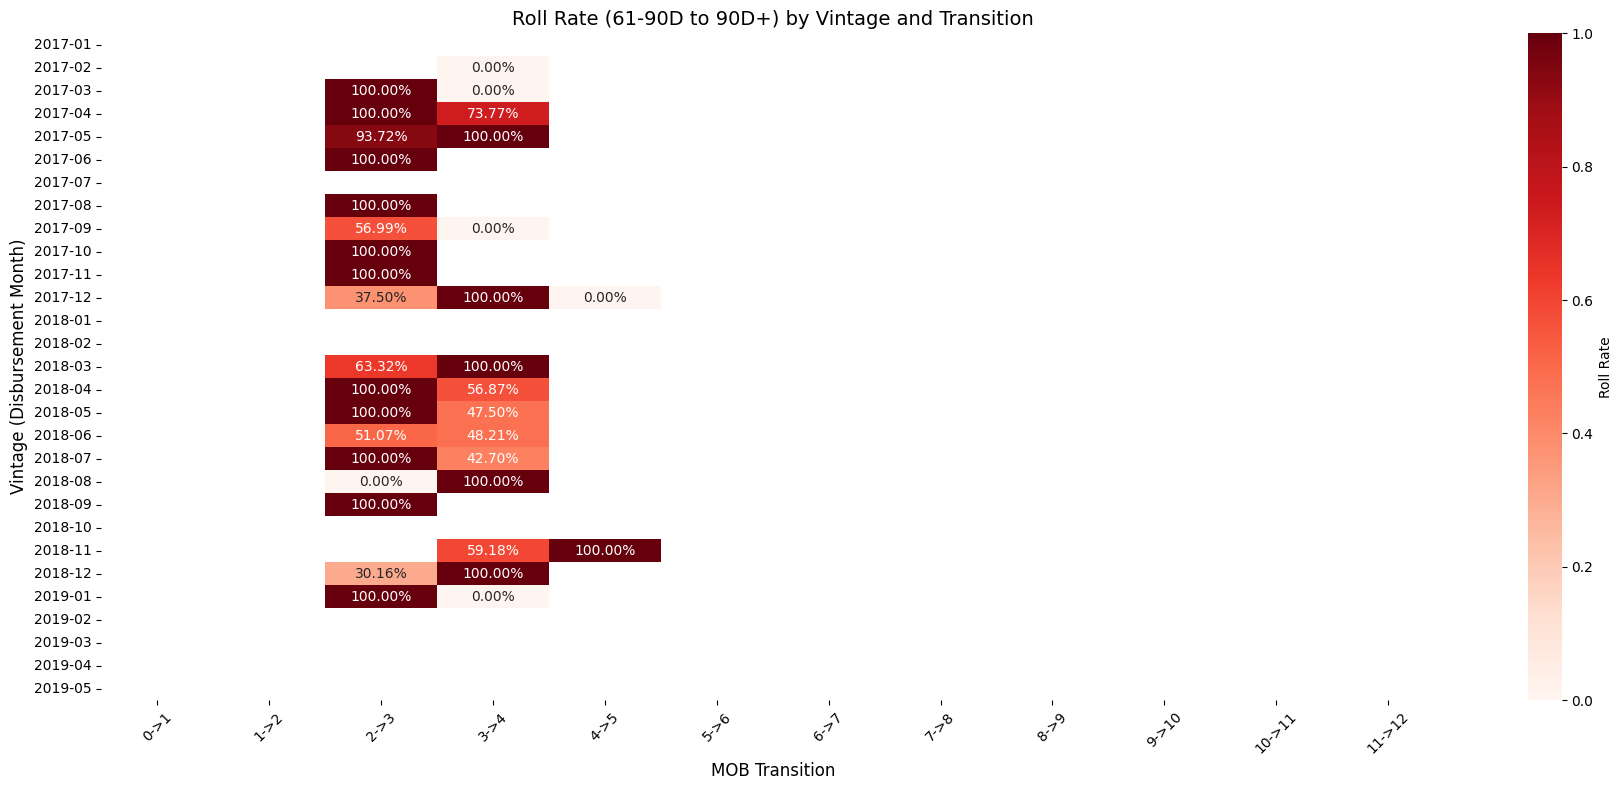

In [230]:
# 1. Filter for   roll rate
heatmap_data = rc_tbl[rc_tbl['roll_pair'] == '61-90D->90D+'].copy()

# 2. Format Y-axis (Period) to just 'YYYY-MM'
heatmap_data['Period_str'] = heatmap_data['Period'].dt.strftime('%Y-%m')

# 3. Force X-axis (transitions) to sort numerically
transitions_ordered = [f'{i}->{i+1}' for i in range(12)]
heatmap_data['transition'] = pd.Categorical(
    heatmap_data['transition'], 
    categories=transitions_ordered, 
    ordered=True
)

# 4. Pivot
pivot_data = heatmap_data.pivot(
    index='Period_str', 
    columns='transition', 
    values='roll_rate'
)

# 5. Plot
plt.figure(figsize=(18, 8))
sns.heatmap(
    pivot_data, 
    annot=True, 
    cmap='Reds', 
    fmt='.2%',     # Shows as 20.26% instead of 0.2026
    cbar_kws={'label': 'Roll Rate'}
)

plt.title('Roll Rate (61-90D to 90D+) by Vintage and Transition', fontsize=14)
plt.ylabel('Vintage (Disbursement Month)', fontsize=12)
plt.xlabel('MOB Transition', fontsize=12)
plt.xticks(rotation=45) # Rotates the X labels so they don't overlap
plt.tight_layout()
plt.show()

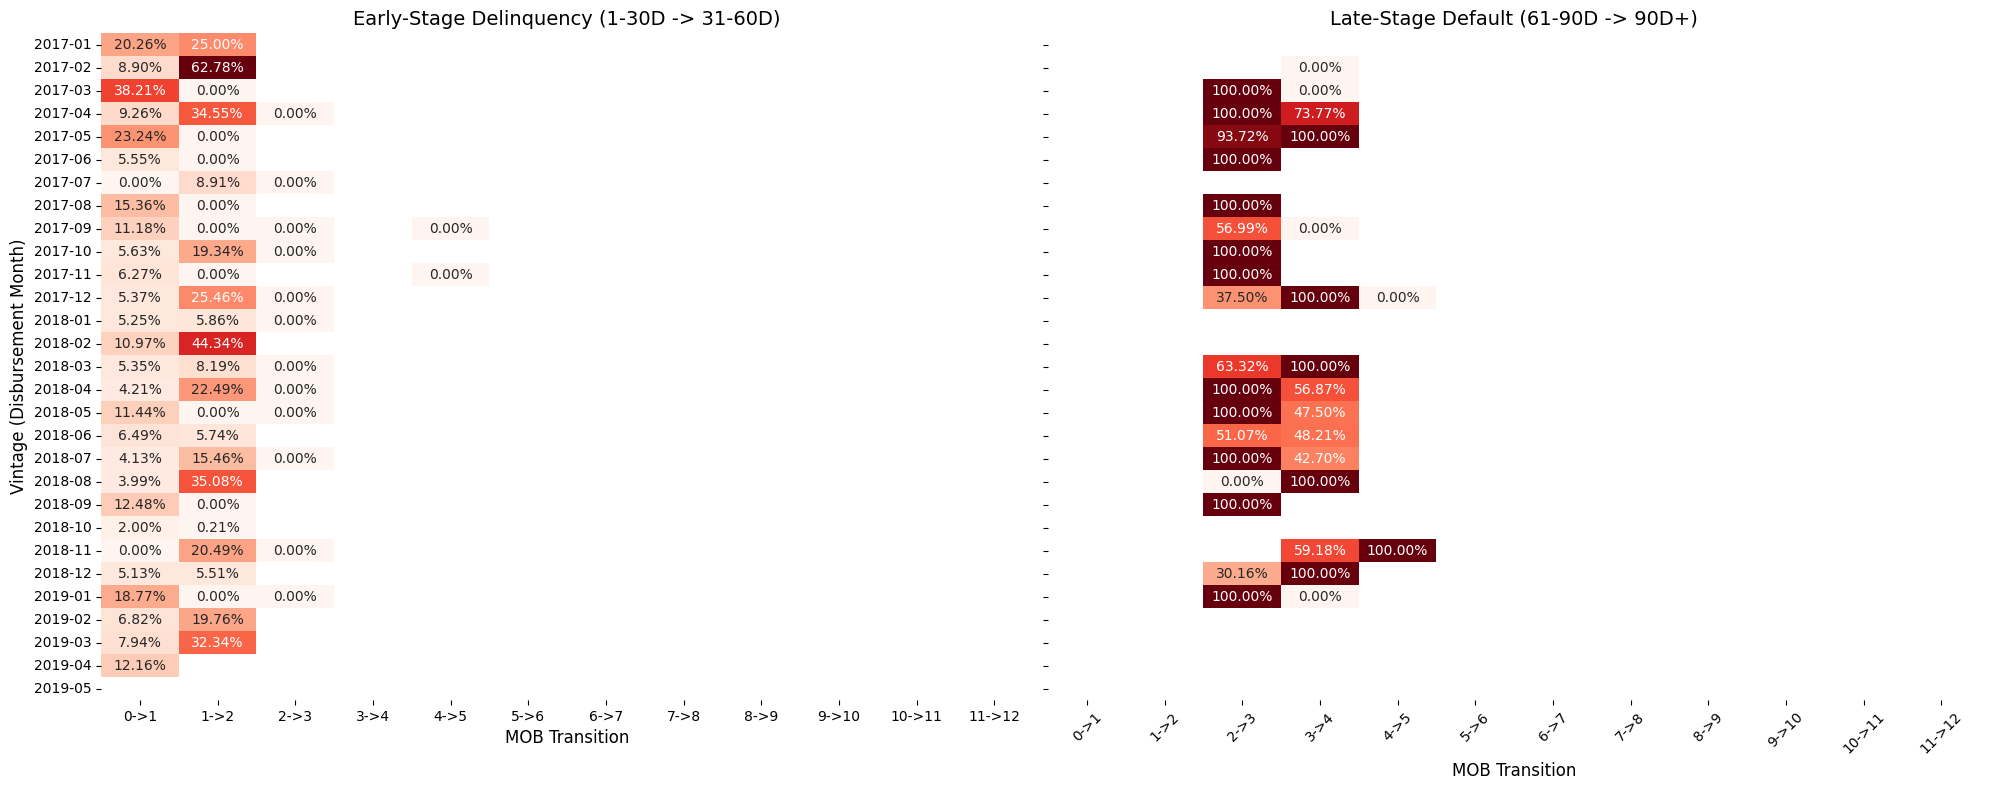

In [232]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Prepare the data
plot_df = rc_tbl[rc_tbl['roll_pair'].isin(['1-30D->31-60D', '61-90D->90D+'])].copy()
plot_df['Period_str'] = plot_df['Period'].dt.strftime('%Y-%m')
transitions_ordered = [f'{i}->{i+1}' for i in range(12)]
plot_df['transition'] = pd.Categorical(plot_df['transition'], categories=transitions_ordered, ordered=True)

# 2. Set up the figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

# --- Subplot 1: Early Stage ---
pivot_early = plot_df[plot_df['roll_pair'] == '1-30D->31-60D'].pivot(
    index='Period_str', columns='transition', values='roll_rate'
)
sns.heatmap(pivot_early, annot=True, cmap='Reds', fmt='.2%', ax=axes[0], cbar=False)
axes[0].set_title('Early-Stage Delinquency (1-30D -> 31-60D)', fontsize=14)
axes[0].set_ylabel('Vintage (Disbursement Month)', fontsize=12)
axes[0].set_xlabel('MOB Transition', fontsize=12)

# --- Subplot 2: Late Stage ---
pivot_late = plot_df[plot_df['roll_pair'] == '61-90D->90D+'].pivot(
    index='Period_str', columns='transition', values='roll_rate'
)
sns.heatmap(pivot_late, annot=True, cmap='Reds', fmt='.2%', ax=axes[1], cbar=False)
axes[1].set_title('Late-Stage Default (61-90D -> 90D+)', fontsize=14)
axes[1].set_ylabel('') # Hide Y-axis label for the second plot
axes[1].set_xlabel('MOB Transition', fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

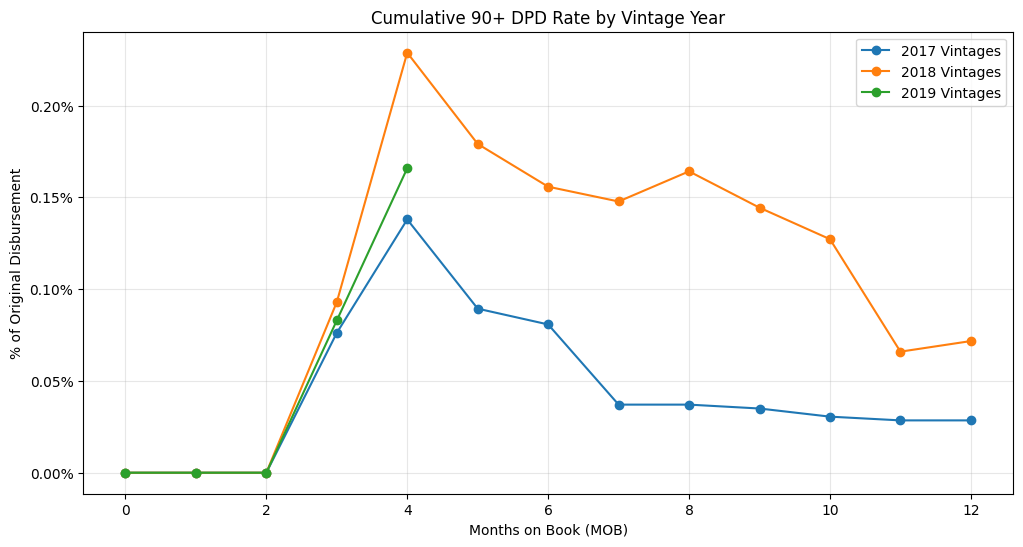

In [233]:
# Calculate Cumulative 90+ DPD as % of original disbursed amount
# Note: p[(1, 'disbursement_amount')] gets the original amount per vintage
cum_90_plus = wide_dec.copy()
cum_90_plus['orig_amount'] = cum_90_plus['Period'].map(p[(1, 'disbursement_amount')])
cum_90_plus['cum_90_rate'] = cum_90_plus['90D+'] / cum_90_plus['orig_amount']

# Plot cumulative 90+ curves for different vintage years
plt.figure(figsize=(12, 6))
# Plot a few sample vintages (e.g., 2017, 2018, 2019)
for year in [2017, 2018, 2019]:
    subset = cum_90_plus[cum_90_plus['Period'].dt.year == year]
    # Group by MOB to get the average curve for that year
    curve = subset.groupby('MOB')['cum_90_rate'].mean()
    plt.plot(curve.index, curve.values, marker='o', label=f'{year} Vintages')

plt.title('Cumulative 90+ DPD Rate by Vintage Year')
plt.xlabel('Months on Book (MOB)')
plt.ylabel('% of Original Disbursement')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:.2%}".format(x)))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [236]:
wide_dec.to_excel('vintage_decomposition_wide.xlsx', index=False)
long_dec.to_excel('vintage_decomposition_long.xlsx', index=False)
rc_tbl.to_excel('roll_cure_rates.xlsx', index=False)
pooled.to_excel('pooled_disbursement_weighted.xlsx', index=False)